# Guía 6 — Parte II: Cuadrivectores, tensor electromagnético y transformaciones

**Electromagnetismo Intermedio · Universidad de Valparaíso · 2026**

Problemas **5–8**. Aquí la "simulación" consiste en tomar en serio que $J^\mu$, $F^{\mu\nu}$ y $U^\mu$ son objetos geométricos y hacer con ellos lo que haría un físico: transformarlos numéricamente entre sistemas inerciales, comprobar qué cambia y qué no, e integrar la ecuación de movimiento covariante.

| Problema | Simulación | Idea central |
|---|---|---|
| 5 | Pulso de carga en el diagrama espacio-tiempo, volumen de control, sistema propio | $\partial_\mu J^\mu=0$ es local e invariante; $\rho$ no lo es |
| 6 | Matrices $F_{\mu\nu}$ y $F^{\mu\nu}$, potenciales, clasificación por invariantes | Subir índices = cambiar signos de la fila/columna 0 |
| 7 | $\mathbf{E}',\mathbf{B}'$ vs. $\beta$; campo de una carga en movimiento obtenido **boosteando Coulomb** | $\mathbf{E}$ y $\mathbf{B}$ son componentes de un mismo tensor |
| 8 | Integración de $dp^\mu/d\tau=qF^{\mu\nu}U_\nu$: ciclotrón, deriva $\mathbf{E}\times\mathbf{B}$, fuga | $\mathbf{B}$ no cambia la energía; la deriva es un boost |

Unidades: $c=1$ y, en el Problema 8, $q/m=1$. `../em_utils.py` implementa $F_{\mu\nu}$, $F^{\mu\nu}$, el boost general $\Lambda^\mu{}_\nu$ y la transformación $F'^{\mu\nu}=\Lambda^\mu{}_\alpha\Lambda^\nu{}_\beta F^{\alpha\beta}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.integrate import solve_ivp, cumulative_trapezoid
from IPython.display import Image, display

import sys, os
sys.path.insert(0, os.path.abspath('..'))   # em_utils.py está en la raíz del repositorio
import em_utils as u
u.estilo()
C = u.COLORES
np.set_printoptions(precision=4, suppress=True)

---
## Problema 5 — Cuadricorriente y conservación de la carga

$\rho(x,t)=\rho_0e^{-(x-ut)^2/\ell^2}$, $\;\mathbf{J}=u\rho\,\hat{x}$, $\;J^\mu=(c\rho,u\rho,0,0)$.

### 1. Diagrama espacio-tiempo

En el plano $(x,ct)$ el pulso es una **banda inclinada** a lo largo de la línea de mundo $x=ut$. El cuadrivector $J^\mu=\rho\,(c,u)$ es paralelo a la cuadrivelocidad, es decir, **tangente a la línea de mundo**. La carga fluye a lo largo de su propia historia.

[guardado] figuras/P5_espaciotiempo_continuidad.png


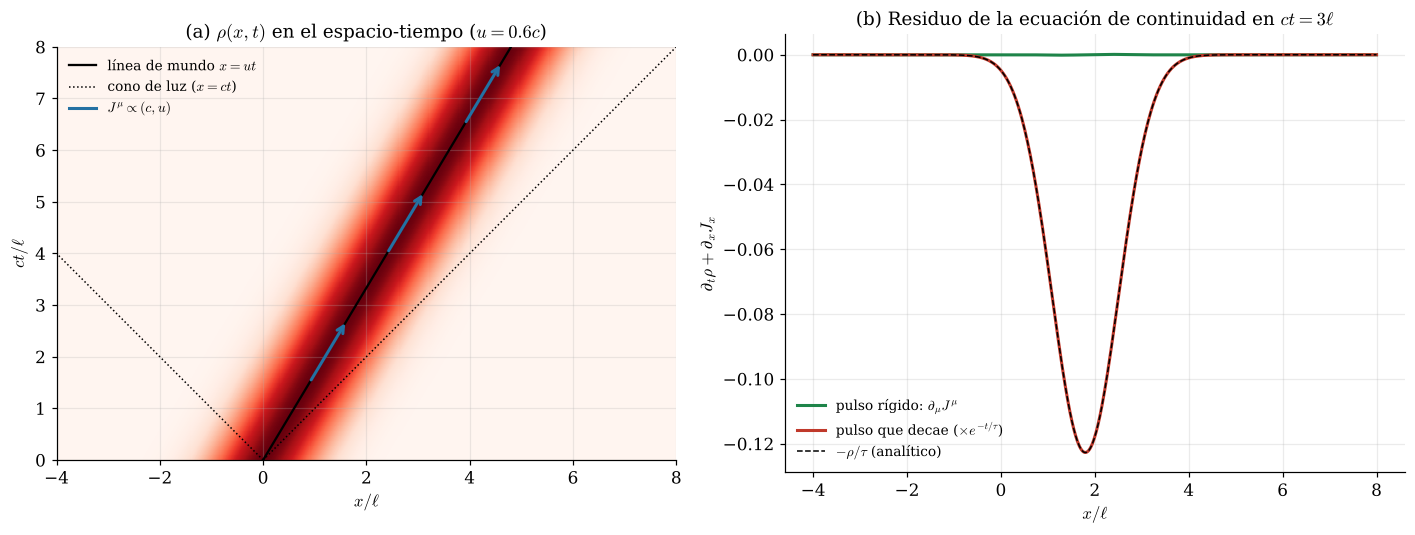

max|∂μJ^μ| pulso rígido = 1.21e-04  (solo error de diferencias finitas, O(h²))
max|∂μJ^μ| pulso que decae = 3.38e-01  -> la carga 'desaparece' sin fluir


In [2]:
uu, ell, rho0 = 0.6, 1.0, 1.0
g_u = 1/np.sqrt(1 - uu**2)
rho = lambda x, t: rho0*np.exp(-(x - uu*t)**2/ell**2)

x = np.linspace(-4, 8, 600); t = np.linspace(0, 8, 500)
X, Tt = np.meshgrid(x, t)
R = rho(X, Tt)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
A = ax[0]
A.pcolormesh(X, Tt, R, cmap='Reds', shading='auto')
A.plot(uu*t, t, 'k-', lw=1.5, label=r'línea de mundo $x=ut$')
A.plot(t, t, 'k:', lw=1, label='cono de luz ($x=ct$)'); A.plot(-t, t, 'k:', lw=1)
for tk in [1.5, 4, 6.5]:
    xk = uu*tk; s = 1.2
    A.annotate('', xy=(xk + s*uu, tk + s*1), xytext=(xk, tk),
               arrowprops=dict(arrowstyle='->', color=C['B'], lw=2))
A.plot([], [], color=C['B'], lw=2, label=r'$J^\mu\propto(c,u)$')
A.set_xlim(-4, 8); A.set_ylim(0, 8); A.set_aspect('equal')
A.set_xlabel('$x/\\ell$'); A.set_ylabel('$ct/\\ell$'); A.set_title('(a) $\\rho(x,t)$ en el espacio-tiempo ($u=0.6c$)')
A.legend(loc='upper left', fontsize=9)

# residuo de continuidad por diferencias finitas
dt = t[1] - t[0]; dx = x[1] - x[0]
def residuo(Rm, Jm):
    return np.gradient(Rm, dt, axis=0) + np.gradient(Jm, dx, axis=1)
res_ok = residuo(R, uu*R)
tau = 3.0
R_mal = R*np.exp(-Tt/tau)               # pulso que "se desvanece" pero con J = u rho
res_mal = residuo(R_mal, uu*R_mal)

A = ax[1]
i0 = np.argmin(np.abs(t - 3))
A.plot(x, res_ok[i0], color=C['v'], lw=2, label=r'pulso rígido: $\partial_\mu J^\mu$')
A.plot(x, res_mal[i0], color=C['E'], lw=2, label=r'pulso que decae ($\times e^{-t/\tau}$)')
A.plot(x, -R_mal[i0]/tau, 'k--', lw=1, label=r'$-\rho/\tau$ (analítico)')
A.set_xlabel('$x/\\ell$'); A.set_ylabel(r'$\partial_t\rho+\partial_x J_x$')
A.set_title('(b) Residuo de la ecuación de continuidad en $ct=3\\ell$'); A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P5_espaciotiempo_continuidad'); plt.show()
print(f"max|∂μJ^μ| pulso rígido = {np.abs(res_ok[5:-5, 5:-5]).max():.2e}  (solo error de diferencias finitas, O(h²))")
print(f"max|∂μJ^μ| pulso que decae = {np.abs(res_mal).max():.2e}  -> la carga 'desaparece' sin fluir")

### 2. Volumen de control: la forma integral de $\partial_\mu J^\mu=0$

Integrando $\partial_t\rho+\partial_xJ_x=0$ entre $x_1$ y $x_2$:

$$\frac{dQ_{[x_1,x_2]}}{dt}=J_x(x_1,t)-J_x(x_2,t),$$

la carga dentro de una caja solo cambia por lo que **entra y sale por sus paredes**. En la animación comparamos la carga contada dentro de la caja con la integral del flujo neto.

In [3]:
x1, x2 = 1.0, 3.0
tt = np.linspace(0, 8, 400)
xs = np.linspace(x1, x2, 400)
Q = np.array([np.trapezoid(rho(xs, tk), xs) for tk in tt])
flujo = uu*rho(x1, tt) - uu*rho(x2, tt)
Q_flujo = Q[0] + cumulative_trapezoid(flujo, tt, initial=0)
print("máx |Q_dentro - (Q0 + ∫ flujo dt)| =", np.abs(Q - Q_flujo).max())

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.5, 6), gridspec_kw={'height_ratios': [1.1, 1]})
xx = np.linspace(-3, 9, 500)
linea, = a1.plot([], [], color=C['E'], lw=2)
a1.axvspan(x1, x2, color='0.85', zorder=0); a1.text(x1 + 0.1, 1.05, 'caja', fontsize=10)
fl1 = a1.annotate('', xy=(x1, 0.5), xytext=(x1, 0.5), arrowprops=dict(arrowstyle='->', color=C['B'], lw=2))
fl2 = a1.annotate('', xy=(x2, 0.5), xytext=(x2, 0.5), arrowprops=dict(arrowstyle='->', color=C['B'], lw=2))
a1.set_xlim(-3, 9); a1.set_ylim(0, 1.2); a1.set_xlabel('$x/\\ell$'); a1.set_ylabel(r'$\rho/\rho_0$')
a1.set_title('Pulso moviéndose; flechas azules: $J_x$ en las paredes')
a2.plot(tt, Q, color='k', lw=2, label=r'$Q$ contada dentro de la caja')
a2.plot(tt[::12], Q_flujo[::12], 'o', color=C['B'], ms=4, label=r'$Q_0+\int(J_1-J_2)\,dt$')
pto, = a2.plot([], [], 'o', color=C['E'], ms=9)
a2.set_xlabel('$ct/\\ell$'); a2.set_ylabel(r'$Q\;[\rho_0\ell]$'); a2.legend(fontsize=9, loc='upper right')
fig.tight_layout()

idx = np.arange(0, len(tt), 6)
def cuadro(j):
    i = idx[j]; tk = tt[i]
    linea.set_data(xx, rho(xx, tk))
    for f, xw in ((fl1, x1), (fl2, x2)):
        Jw = uu*rho(xw, tk)
        f.xy = (xw + 3*Jw, 0.6); f.set_position((xw, 0.6))
    pto.set_data([tk], [Q[i]])
    return linea, pto
anim = animation.FuncAnimation(fig, cuadro, frames=len(idx))
u.guardar_gif(anim, 'P5_animacion_volumen_control', fps=15)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P5_animacion_volumen_control.gif)

máx |Q_dentro - (Q0 + ∫ flujo dt)| = 2.1991295454437676e-05


[guardado] figuras/P5_animacion_volumen_control.gif  (0.49 MB)


![animación](figuras/P5_animacion_volumen_control.gif)

### 3. ¿Qué es invariante? Transformación al sistema propio del pulso

Hacemos un boost con $\boldsymbol\beta=u\hat{x}$ y transformamos **numéricamente** tanto las coordenadas de cada evento como el cuadrivector $J^\mu$: $J'^\mu=\Lambda^\mu{}_\nu J^\nu$. En el sistema propio:

- $J'^1=0$: no hay corriente.
- $\rho'=\rho/\gamma$: la densidad es *menor*.
- El pulso es *más ancho* ($\gamma\ell$): en el laboratorio está contraído.
- La carga total $Q=\int\rho\,dx$ es **la misma**, porque la carga es un escalar de Lorentz.
- $J^\mu J_\mu=c^2\rho^2-u^2\rho^2=c^2\rho_{\rm propia}^2$ es invariante evento a evento.

máx |J'^1| en el sistema propio  = 1.3877787807814457e-16
máx |J·J (lab) - J·J (propio)|   = 3.3306690738754696e-16
Q laboratorio = 1.772454,  Q propio = 1.772454,  √π ρ0 ℓ = 1.772454
[guardado] figuras/P5_sistema_propio_densidad.png


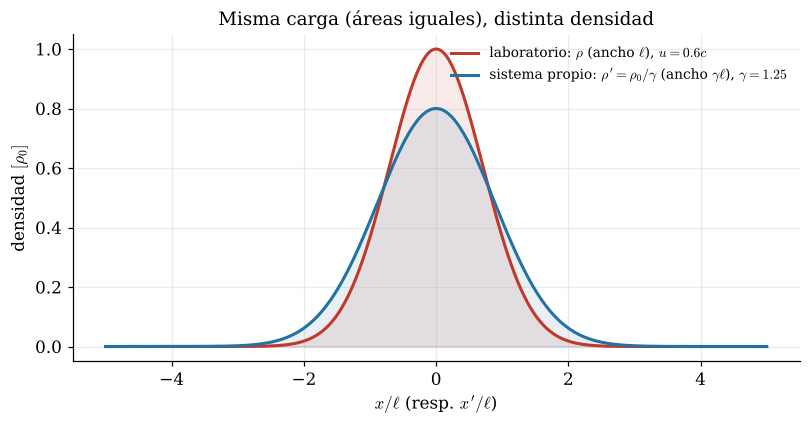

In [4]:
L = u.matriz_boost([uu, 0, 0])
xp = np.linspace(-5, 5, 2001)           # coordenada x' en el sistema propio, a t' = 0
# evento (ct', x') -> (ct, x) en el laboratorio:  x^mu = Lambda^{-1} x'^mu
Linv = np.linalg.inv(L)
ev_p = np.stack([0*xp, xp, 0*xp, 0*xp], -1)
ev = ev_p @ Linv.T
r_lab = rho(ev[:, 1], ev[:, 0])
J_lab = np.stack([r_lab, uu*r_lab, 0*r_lab, 0*r_lab], -1)      # c = 1
J_prop = J_lab @ L.T
print("máx |J'^1| en el sistema propio  =", np.abs(J_prop[:, 1]).max())
JJ_lab = np.einsum('ni,ij,nj->n', J_lab, u.ETA, J_lab)
JJ_prop = np.einsum('ni,ij,nj->n', J_prop, u.ETA, J_prop)
print("máx |J·J (lab) - J·J (propio)|   =", np.abs(JJ_lab - JJ_prop).max())

x_lab = np.linspace(-5, 5, 2001)
Q_lab = np.trapezoid(rho(x_lab, 0), x_lab); Q_prop = np.trapezoid(J_prop[:, 0], xp)
print(f"Q laboratorio = {Q_lab:.6f},  Q propio = {Q_prop:.6f},  √π ρ0 ℓ = {np.sqrt(np.pi):.6f}")

fig, A = plt.subplots(figsize=(7.5, 4))
A.plot(x_lab, rho(x_lab, 0), color=C['E'], lw=2, label=fr'laboratorio: $\rho$ (ancho $\ell$), $u={uu}c$')
A.plot(xp, J_prop[:, 0], color=C['B'], lw=2, label=fr"sistema propio: $\rho'=\rho_0/\gamma$ (ancho $\gamma\ell$), $\gamma={g_u:.2f}$")
A.fill_between(x_lab, rho(x_lab, 0), color=C['E'], alpha=0.1); A.fill_between(xp, J_prop[:, 0], color=C['B'], alpha=0.1)
A.set_xlabel('$x/\\ell$ (resp. $x\'/\\ell$)'); A.set_ylabel(r'densidad $[\rho_0]$')
A.set_title('Misma carga (áreas iguales), distinta densidad'); A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P5_sistema_propio_densidad'); plt.show()

---
## Problema 6 — De los potenciales al tensor $F_{\mu\nu}$

$\phi=-E_0x$, $\mathbf{A}=B_0x\,\hat{y}$ $\Rightarrow$ $\mathbf{E}=E_0\hat{x}$, $\mathbf{B}=B_0\hat{z}$.

Visualizamos:

1. Los potenciales. $\mathbf{A}=B_0x\hat{y}$ es un campo "de cizalle": no es uniforme, pero su rotor sí lo es.
2. Las matrices $F_{\mu\nu}$ y $F^{\mu\nu}$, para ver concretamente que subir los dos índices **solo cambia el signo de la fila y la columna 0** (un índice espacial aporta un $-1$; dos aportan $+1$).

In [5]:
E0, B0 = 1.0, 0.6
E = np.array([E0, 0, 0]); B = np.array([0, 0, B0])
Fd = u.F_abajo(E, B); Fu = u.subir(Fd)

# F desde los potenciales por diferencias finitas (independiente de la fórmula F_{0i}=E_i/c)
h = 1e-5
def A_cov(xv):                       # A_mu = (phi/c, -A)
    xx = xv[1]
    return np.array([-E0*xx, 0, -B0*xx, 0])
x0 = np.array([0.3, 0.7, -0.2, 0.5])  # un evento cualquiera (ct, x, y, z)
dA = np.array([(A_cov(x0 + h*np.eye(4)[m]) - A_cov(x0 - h*np.eye(4)[m]))/(2*h) for m in range(4)])  # dA[m, n] = ∂_m A_n
F_num = dA - dA.T
print("F_{μν} desde la definición ∂μAν - ∂νAμ (numérico):\n", F_num)
print("¿coincide con F_{0i}=E_i/c, F_{ij}=-ε_{ijk}B_k?", np.allclose(F_num, Fd))
print(f"F_μν F^μν = {u.FF(Fd):.4f}   vs   2(B0² - E0²/c²) = {2*(B0**2 - E0**2):.4f}")

F_{μν} desde la definición ∂μAν - ∂νAμ (numérico):
 [[ 0.   1.   0.   0. ]
 [-1.   0.  -0.6  0. ]
 [ 0.   0.6  0.   0. ]
 [ 0.   0.   0.   0. ]]
¿coincide con F_{0i}=E_i/c, F_{ij}=-ε_{ijk}B_k? True
F_μν F^μν = -1.2800   vs   2(B0² - E0²/c²) = -1.2800


[guardado] figuras/P6_potenciales_y_matrices_F.png


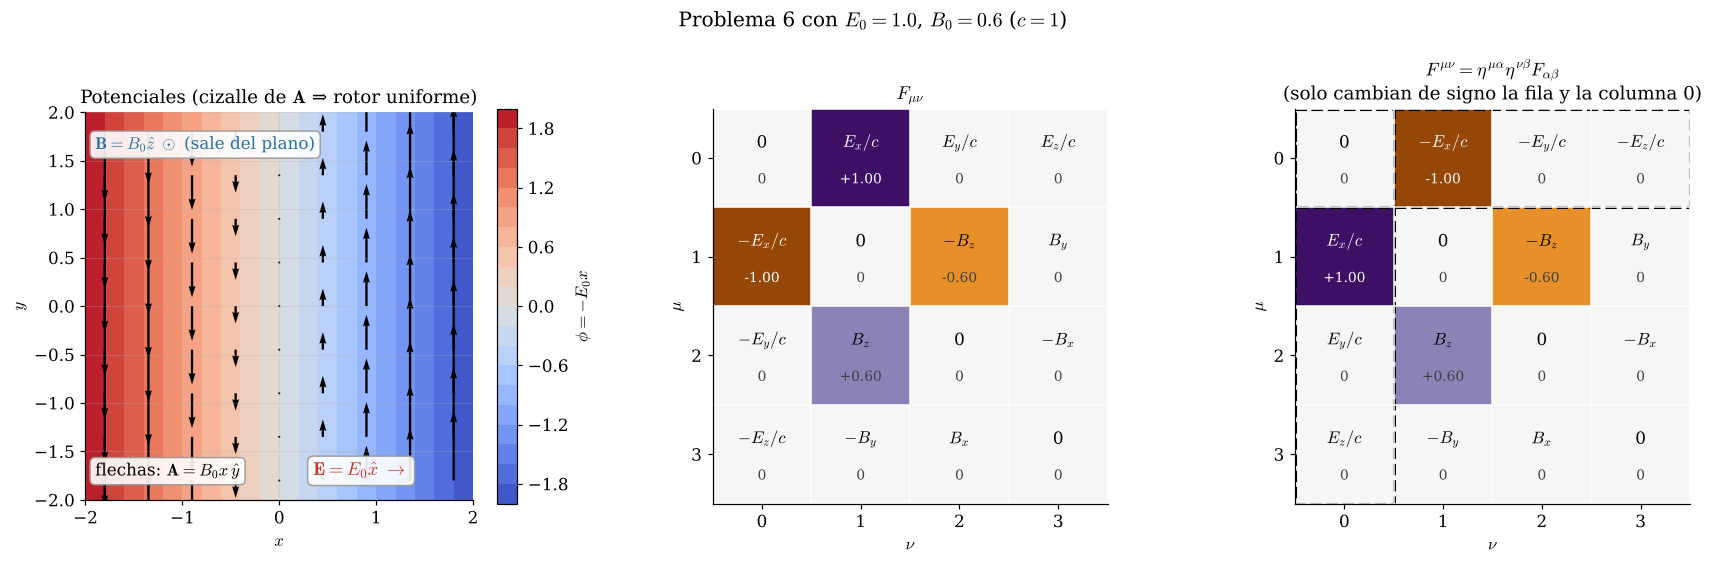

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
A = ax[0]
xg, yg = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
cs = A.contourf(xg, yg, -E0*xg, levels=20, cmap='coolwarm')
plt.colorbar(cs, ax=A, label=r'$\phi=-E_0x$')
xq, yq = np.meshgrid(np.linspace(-1.8, 1.8, 9), np.linspace(-1.8, 1.8, 9))
A.quiver(xq, yq, 0*xq, B0*xq, color='k', scale=6, width=0.006)
caja = dict(boxstyle='round', fc='w', ec='0.6', alpha=0.9)
A.text(0.35, -1.75, r'$\mathbf{E}=E_0\hat{x}\;\rightarrow$', color=C['E'], fontsize=12, bbox=caja)
A.text(-1.9, -1.75, r'flechas: $\mathbf{A}=B_0x\,\hat{y}$', fontsize=11, bbox=caja)
A.text(-1.9, 1.62, r'$\mathbf{B}=B_0\hat{z}\;\odot$ (sale del plano)', color=C['B'], fontsize=11, bbox=caja)
A.set_aspect('equal'); A.set_xlabel('$x$'); A.set_ylabel('$y$'); A.set_title('Potenciales (cizalle de $\\mathbf{A}$ ⇒ rotor uniforme)')

etq_d = [['0', r'$E_x/c$', r'$E_y/c$', r'$E_z/c$'],
         [r'$-E_x/c$', '0', r'$-B_z$', r'$B_y$'],
         [r'$-E_y/c$', r'$B_z$', '0', r'$-B_x$'],
         [r'$-E_z/c$', r'$-B_y$', r'$B_x$', '0']]
signo_u = np.array([[1, -1, -1, -1], [-1, 1, 1, 1], [-1, 1, 1, 1], [-1, 1, 1, 1]])
for A, M, tit, sg in [(ax[1], Fd, r'$F_{\mu\nu}$', np.ones((4, 4))), (ax[2], Fu, r'$F^{\mu\nu}=\eta^{\mu\alpha}\eta^{\nu\beta}F_{\alpha\beta}$', signo_u)]:
    A.imshow(M, cmap='PuOr', vmin=-1.1, vmax=1.1)
    for i in range(4):
        for j in range(4):
            lab = etq_d[i][j]
            if sg[i, j] < 0 and lab != '0':
                lab = lab.replace('$-', '$') if lab.startswith('$-') else '$-' + lab[1:]
            A.text(j, i - 0.15, lab, ha='center', va='center', fontsize=11, color='w' if abs(M[i, j]) > 0.7 else 'k')
            A.text(j, i + 0.22, f'{M[i, j]:+.2f}' if M[i, j] != 0 else '0', ha='center', va='center', fontsize=9, color='w' if abs(M[i, j]) > 0.7 else '0.25')
    A.set_xticks(range(4)); A.set_yticks(range(4)); A.set_xticklabels(['0', '1', '2', '3']); A.set_yticklabels(['0', '1', '2', '3'])
    A.set_xlabel(r'$\nu$'); A.set_ylabel(r'$\mu$'); A.set_title(tit); A.grid(False)
    for k in np.arange(-0.5, 4, 1):
        A.axhline(k, color='w', lw=1); A.axvline(k, color='w', lw=1)
ax[2].add_patch(plt.Rectangle((-0.5, -0.5), 4, 1, fill=False, ec='k', lw=2, ls='--'))
ax[2].add_patch(plt.Rectangle((-0.5, -0.5), 1, 4, fill=False, ec='k', lw=2, ls='--'))
ax[2].set_title(r'$F^{\mu\nu}=\eta^{\mu\alpha}\eta^{\nu\beta}F_{\alpha\beta}$' + '\n(solo cambian de signo la fila y la columna 0)')
fig.suptitle(fr'Problema 6 con $E_0={E0}$, $B_0={B0}$ ($c=1$)', y=1.0)
fig.tight_layout(); u.guardar(fig, 'P6_potenciales_y_matrices_F'); plt.show()

### Lo que dice el invariante $F_{\mu\nu}F^{\mu\nu}=2(B^2-E^2/c^2)$

Para campos cruzados ($\mathbf{E}\cdot\mathbf{B}=0$, como aquí), el signo de $F_{\mu\nu}F^{\mu\nu}$ decide qué se puede "eliminar" con un boost:

- $E<cB$ ($FF>0$): existe un sistema que se mueve con $\mathbf{v}_d=\mathbf{E}\times\mathbf{B}/B^2$ donde **$\mathbf{E}'=0$**. El campo es "magnético en esencia".
- $E>cB$ ($FF<0$): con $\mathbf{v}=c^2\,\mathbf{E}\times\mathbf{B}/E^2$ se elimina $\mathbf{B}$. Es el caso del Problema 7.

Lo comprobamos con el boost general de `em_utils`. Esto prepara el Problema 8: la deriva $\mathbf{E}\times\mathbf{B}$ es exactamente este boost.

In [7]:
for E0_, B0_ in [(0.6, 1.0), (1.0, 0.6)]:
    E_ = np.array([E0_, 0, 0]); B_ = np.array([0, 0, B0_])
    S = np.cross(E_, B_)
    beta = S/B0_**2 if E0_ < B0_ else S/E0_**2
    Ep, Bp = u.boost_campos(E_, B_, beta)
    print(f"E0={E0_}, B0={B0_}:  FF = {2*(B0_**2 - E0_**2):+.2f},  boost β = {beta}")
    print(f"     E' = {Ep},   B' = {Bp}   ->  invariante E'²-B'² = {Ep@Ep - Bp@Bp:+.4f} (antes {E0_**2 - B0_**2:+.4f})")

E0=0.6, B0=1.0:  FF = +1.28,  boost β = [ 0.  -0.6  0. ]
     E' = [0. 0. 0.],   B' = [-0.  -0.   0.8]   ->  invariante E'²-B'² = -0.6400 (antes -0.6400)
E0=1.0, B0=0.6:  FF = -1.28,  boost β = [ 0.  -0.6  0. ]
     E' = [0.8 0.  0. ],   B' = [-0. -0. -0.]   ->  invariante E'²-B'² = +0.6400 (antes +0.6400)


---
## Problema 7 — Un campo puramente eléctrico visto desde otro sistema

$\mathbf{E}=E_0\hat{y}$, $\mathbf{B}=0$ en $S$; $S'$ se mueve con $v\hat{x}$:

$$\mathbf{E}'=\gamma E_0\hat{y},\qquad \mathbf{B}'=-\gamma\frac{vE_0}{c^2}\hat{z} .$$

### 1. Barrido en $\beta$: cambian los campos, no los invariantes

¿E'_y = γE0?           True
¿B'_z = -γvE0/c²?      True


[guardado] figuras/P7_campos_e_invariantes_vs_beta.png


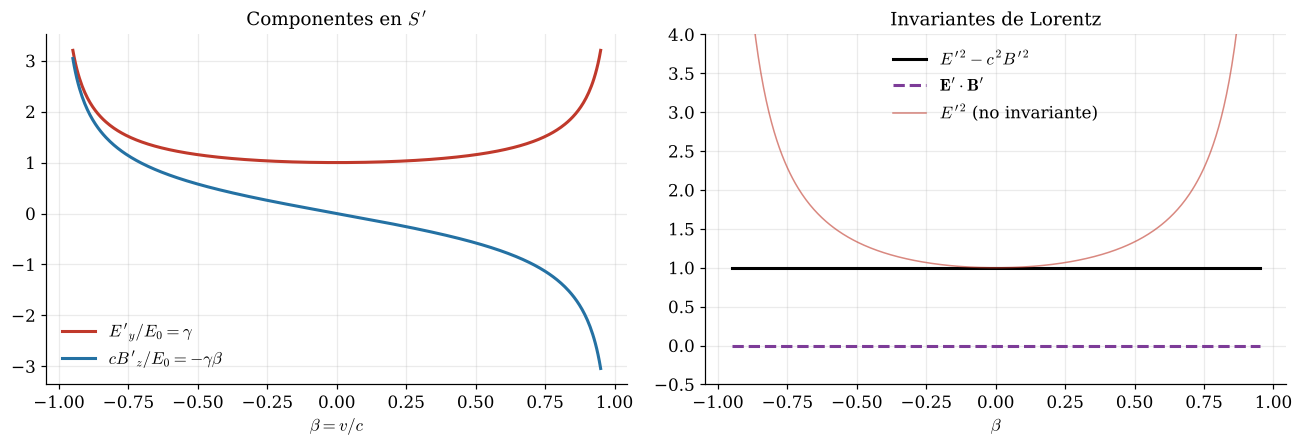

In [8]:
E0 = 1.0
bs = np.linspace(-0.95, 0.95, 400)
Ep = np.array([u.boost_campos([0, E0, 0], [0, 0, 0], [b, 0, 0])[0] for b in bs])
Bp = np.array([u.boost_campos([0, E0, 0], [0, 0, 0], [b, 0, 0])[1] for b in bs])
g = 1/np.sqrt(1 - bs**2)
print("¿E'_y = γE0?          ", np.allclose(Ep[:, 1], g*E0))
print("¿B'_z = -γvE0/c²?     ", np.allclose(Bp[:, 2], -g*bs*E0))
I1, I2 = u.invariantes(Ep, Bp)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
A = ax[0]
A.plot(bs, Ep[:, 1], color=C['E'], lw=2, label=r"$E'_y/E_0=\gamma$")
A.plot(bs, Bp[:, 2], color=C['B'], lw=2, label=r"$cB'_z/E_0=-\gamma\beta$")
A.set_xlabel(r'$\beta=v/c$'); A.set_title('Componentes en $S\'$'); A.legend()
A = ax[1]
A.plot(bs, I1, color='k', lw=2, label=r"$E'^2-c^2B'^2$")
A.plot(bs, I2, color=C['S'], lw=2, ls='--', label=r"$\mathbf{E}'\cdot\mathbf{B}'$")
A.plot(bs, Ep[:, 1]**2, color=C['E'], lw=1, alpha=0.6, label=r"$E'^2$ (no invariante)")
A.set_ylim(-0.5, 4); A.set_xlabel(r'$\beta$'); A.set_title('Invariantes de Lorentz'); A.legend()
fig.tight_layout(); u.guardar(fig, 'P7_campos_e_invariantes_vs_beta'); plt.show()

### 2. Interpretación física: boosteando el campo de Coulomb

¿De dónde sale $\mathbf{B}'$? En $S'$ las cargas fuente se **mueven** con $-v\hat{x}$, y cargas en movimiento son una corriente. Para verlo concretamente, tomamos una carga en reposo en el origen de $S$ (campo de Coulomb puro) y la transformamos *punto a punto* a $S'$:

1. Un evento en $S'$ a $t'=0$, posición $\mathbf{x}'$, corresponde a $x=\gamma x'$, $y=y'$, $z=z'$ en $S$ (y algún $t$, irrelevante porque el campo es estático).
2. Evaluamos $\mathbf{E}_{\rm Coulomb}(\mathbf{x})$ y aplicamos la transformación de $F^{\mu\nu}$.

El resultado debe coincidir con el campo de una carga en movimiento uniforme (Heaviside–Feynman), medido desde la posición **presente** de la carga:

$$\mathbf{E}'=\frac{q}{4\pi\varepsilon_0}\frac{1-\beta^2}{(1-\beta^2\sin^2\theta)^{3/2}}\frac{\hat{\mathbf{R}}}{R^2},\qquad \mathbf{B}'=\frac{1}{c^2}\mathbf{v}_q\times\mathbf{E}'.$$

El campo sigue siendo **radial**, pero se comprime hacia el plano perpendicular al movimiento como un "panqueque": a $90^\circ$ crece un factor $\gamma$ (de ahí $E'_y=\gamma E_y$) y en la dirección del movimiento se reduce en $1/\gamma^2$.

In [9]:
def campo_heaviside(P, beta):
    Rn = np.linalg.norm(P, axis=-1, keepdims=True)
    sin2 = 1 - (P[..., :1]/Rn)**2                  # theta medido desde la dirección de movimiento (eje x)
    return (1 - beta**2)/(1 - beta**2*sin2)**1.5*P/Rn**3

beta = 0.8; gb = 1/np.sqrt(1 - beta**2)
rng = np.random.default_rng(1)
Pp = rng.uniform(-3, 3, (2000, 3))                   # puntos x' en S' a t'=0
Ps = Pp.copy(); Ps[:, 0] *= gb                       # x = γ x'
E_coul = Ps/np.linalg.norm(Ps, axis=1, keepdims=True)**3
Ep_list, Bp_list = zip(*[u.boost_campos(E_coul[i], [0, 0, 0], [beta, 0, 0]) for i in range(len(Ps))])
Ep_b = np.array(Ep_list); Bp_b = np.array(Bp_list)
E_hf = campo_heaviside(Pp, beta)
B_hf = np.cross([-beta, 0, 0], E_hf)                 # la carga se mueve con -v x̂ en S'
print("error relativo máx  E' (boost de Coulomb vs Heaviside):", np.max(np.linalg.norm(Ep_b - E_hf, axis=1)/np.linalg.norm(E_hf, axis=1)))
print("error relativo máx  B'                             :", np.max(np.linalg.norm(Bp_b - B_hf, axis=1)/np.linalg.norm(B_hf, axis=1)))

error relativo máx  E' (boost de Coulomb vs Heaviside): 1.212188407362055e-15
error relativo máx  B'                             : 1.1365269882408574e-15


[guardado] figuras/P7_carga_en_movimiento_panqueque.png


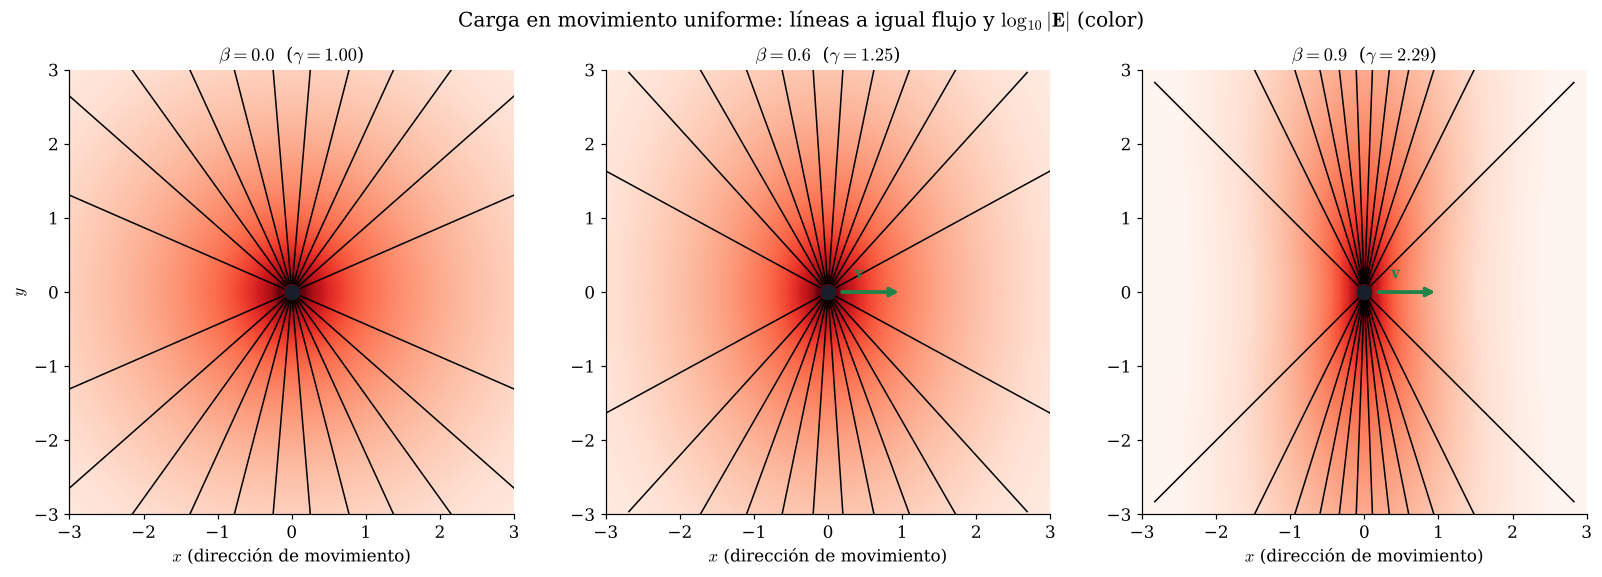

In [10]:
from scipy.integrate import quad
from scipy.interpolate import interp1d

def angulos_lineas(beta, N=24):
    # líneas de campo radiales espaciadas a igual flujo:
    # Φ(θ) ∝ ∫_0^θ (1-β²) sinθ'/(1-β² sin²θ')^{3/2} dθ'  (θ desde el eje de movimiento)
    th = np.linspace(0, np.pi, 2001)
    f = (1 - beta**2)*np.sin(th)/(1 - beta**2*np.sin(th)**2)**1.5
    Phi = cumulative_trapezoid(f, th, initial=0); Phi /= Phi[-1]
    inv = interp1d(Phi, th)
    return inv((np.arange(N//2) + 0.5)/(N//2))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
xg, yg = np.meshgrid(np.linspace(-3, 3, 400), np.linspace(-3, 3, 400))
for A, be in zip(ax, [0.0, 0.6, 0.9]):
    P = np.stack([xg, yg, 0*xg], -1)
    Em = np.linalg.norm(campo_heaviside(P, be), axis=-1)
    A.pcolormesh(xg, yg, np.log10(Em), cmap='Reds', vmin=-1.5, vmax=1.5, shading='auto')
    for th in angulos_lineas(be):
        for sgn in (1, -1):
            A.plot([0.12*np.cos(th), 4*np.cos(th)], [sgn*0.12*np.sin(th), sgn*4*np.sin(th)], color='k', lw=1)
    A.plot(0, 0, 'o', color=C['carga'], ms=9)
    if be > 0:
        A.annotate('', xy=(1.0, 0), xytext=(0.15, 0), arrowprops=dict(arrowstyle='->', color=C['v'], lw=2.5))
        A.text(0.35, 0.18, r'$\mathbf{v}$', color=C['v'], fontsize=13)
    A.set_aspect('equal'); A.set_xlim(-3, 3); A.set_ylim(-3, 3); A.grid(False)
    A.set_title(fr'$\beta={be}$  ($\gamma={1/np.sqrt(1-be**2):.2f}$)')
    A.set_xlabel('$x$ (dirección de movimiento)')
ax[0].set_ylabel('$y$')
fig.suptitle('Carga en movimiento uniforme: líneas a igual flujo y $\\log_{10}|\\mathbf{E}|$ (color)', y=1.0)
fig.tight_layout(); u.guardar(fig, 'P7_carga_en_movimiento_panqueque'); plt.show()

---
## Problema 8 — De la fuerza covariante a la fuerza de Lorentz

Integramos directamente la ecuación **covariante**

$$\frac{dx^\mu}{d\tau}=U^\mu,\qquad \frac{dU^\mu}{d\tau}=\frac{q}{m}F^{\mu\nu}U_\nu=\frac qmF^{\mu\nu}\eta_{\nu\sigma}U^\sigma ,$$

en las 8 variables $(x^\mu,U^\mu)$ y con el tiempo propio como parámetro. Nunca escribimos $\mathbf{v}\times\mathbf{B}$: la fuerza de Lorentz y el teorema trabajo–energía deben **salir solos**. Usamos los campos del Problema 6, $\mathbf{E}=E_0\hat{x}$ y $\mathbf{B}=B_0\hat{z}$.

Comprobaciones numéricas:

1. $U^\mu U_\mu=c^2$ se conserva. La antisimetría de $F$ garantiza $U_\mu\,dU^\mu/d\tau=\frac qmF^{\mu\nu}U_\mu U_\nu=0$.
2. $d\mathcal E/dt=q\,\mathbf{E}\cdot\mathbf{v}$ (componente $\mu=0$).
3. Con $E_0=0$, $\gamma$ es constante: **$\mathbf{B}$ no hace trabajo**.

In [11]:
def integrar(E0, B0, U0_vec=(0, 0, 0), tau_max=60, n=6000):
    Fu = u.subir(u.F_abajo([E0, 0, 0], [0, 0, B0]))
    M = Fu @ u.ETA                          # F^{mu}_{sigma}
    def rhs(tau, y):
        return np.concatenate([y[4:], M @ y[4:]])
    U0 = np.array(U0_vec, float); g0 = np.sqrt(1 + U0 @ U0)
    y0 = np.concatenate([[0, 0, 0, 0], [g0], U0])
    taus = np.linspace(0, tau_max, n)
    sol = solve_ivp(rhs, (0, tau_max), y0, t_eval=taus, method='DOP853', rtol=1e-11, atol=1e-12)
    x, U = sol.y[:4].T, sol.y[4:].T
    return taus, x, U

casos = {
    'ciclotrón ($E_0=0$)':          dict(E0=0.0, B0=1.0, U0_vec=(0, 0.75, 0)),
    'deriva $E_0=0.5\\,cB_0$':       dict(E0=0.5, B0=1.0),
    'crítico $E_0=cB_0$':           dict(E0=1.0, B0=1.0, tau_max=12),
    'fuga $E_0=1.5\\,cB_0$':        dict(E0=1.5, B0=1.0, tau_max=6),
}
res = {k: integrar(**v) for k, v in casos.items()}

for k, (tau, x, U) in res.items():
    norma = np.einsum('ni,ij,nj->n', U, u.ETA, U)
    t = x[:, 0]; gam = U[:, 0]; v = U[:, 1:]/gam[:, None]
    E0 = casos[k]['E0']
    dE_dt = np.gradient(gam, t)                     # m = 1, c = 1  -> energía = γ
    potencia = E0*v[:, 0]                           # q E·v
    if E0 == 0:
        txt = f"max|dγ/dt| = {np.abs(dE_dt).max():.1e} (B no hace trabajo)"
    else:
        err = np.max(np.abs(dE_dt[5:-5] - potencia[5:-5]))/np.abs(potencia).max()
        txt = f"error rel. dE/dt vs qE·v = {err:.1e}"
    print(f"{k:28s}  max|U·U-1| = {np.abs(norma - 1).max():.1e}   {txt}   γ_final = {gam[-1]:.3f}")

ciclotrón ($E_0=0$)           max|U·U-1| = 4.6e-11   max|dγ/dt| = 1.4e-14 (B no hace trabajo)   γ_final = 1.250
deriva $E_0=0.5\,cB_0$        max|U·U-1| = 4.1e-11   error rel. dE/dt vs qE·v = 1.8e-05   γ_final = 1.375
crítico $E_0=cB_0$            max|U·U-1| = 1.4e-12   error rel. dE/dt vs qE·v = 1.3e-06   γ_final = 73.000
fuga $E_0=1.5\,cB_0$          max|U·U-1| = 6.1e-10   error rel. dE/dt vs qE·v = 5.5e-07   γ_final = 736.389


[guardado] figuras/P8_trayectorias_covariantes.png


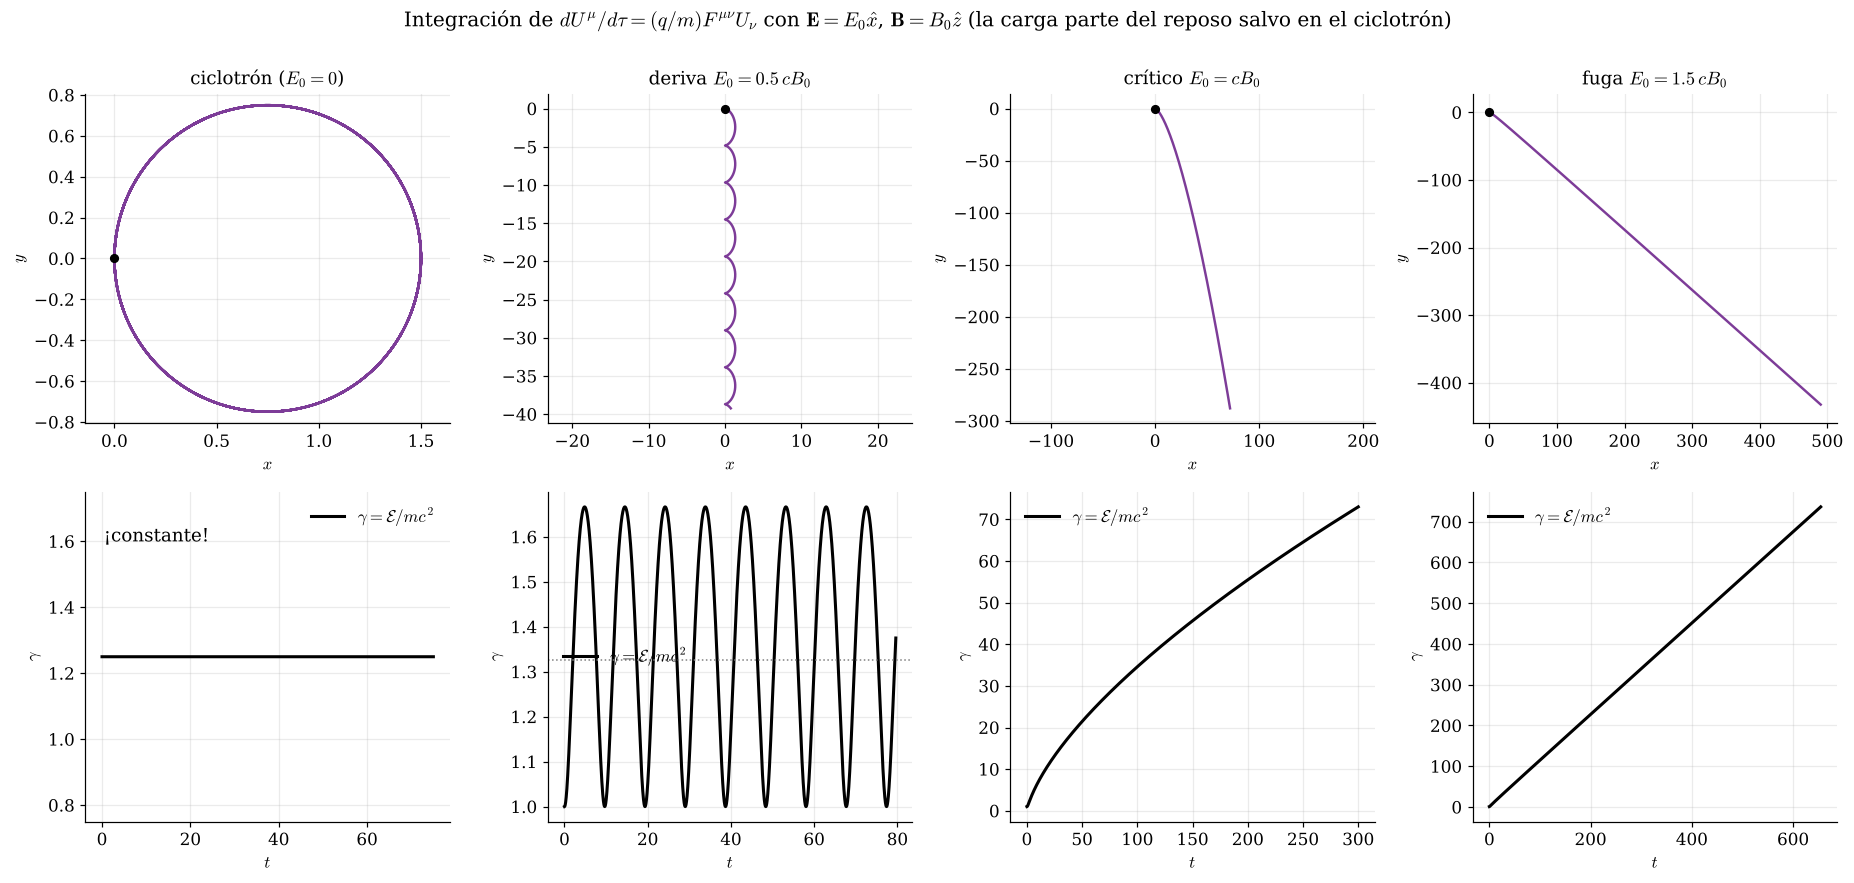

In [12]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8))
for j, (k, (tau, x, U)) in enumerate(res.items()):
    A = ax[0, j]
    A.plot(x[:, 1], x[:, 2], color=C['S'], lw=1.6)
    A.plot(0, 0, 'ko', ms=5)
    A.set_aspect('equal', adjustable='datalim'); A.set_title(k); A.set_xlabel('$x$'); A.set_ylabel('$y$')
    A = ax[1, j]
    t = x[:, 0]; gam = U[:, 0]
    A.plot(t, gam, color='k', lw=2, label=r'$\gamma=\mathcal{E}/mc^2$')
    A.set_xlabel('$t$'); A.set_ylabel(r'$\gamma$')
    if j == 0:
        A.set_ylim(gam[0] - 0.5, gam[0] + 0.5); A.text(0.05, 0.85, '¡constante!', transform=A.transAxes, fontsize=12)
    if j == 1:
        A.axhline(gam.mean(), color='0.5', ls=':', lw=1)
    A.legend(loc='best')
fig.suptitle(r'Integración de $dU^\mu/d\tau=(q/m)F^{\mu\nu}U_\nu$ con $\mathbf{E}=E_0\hat{x}$, $\mathbf{B}=B_0\hat{z}$ (la carga parte del reposo salvo en el ciclotrón)', y=1.0)
fig.tight_layout(); u.guardar(fig, 'P8_trayectorias_covariantes'); plt.show()

**Lectura.**

- **Ciclotrón**: órbita circular con $\gamma$ constante. La fuerza magnética es perpendicular a $\mathbf{v}$ y no hace trabajo (inciso (c)).
- **Deriva** ($E<cB$): cicloide que avanza en $-\hat{y}$, la dirección de $\mathbf{E}\times\mathbf{B}$. La energía oscila: el campo eléctrico hace trabajo positivo y negativo, y en promedio no hay ganancia neta.
- **Crítico** ($E=cB$) y **fuga** ($E>cB$): no existe sistema donde $\mathbf{E}'=0$ (Problema 6), y la partícula se acelera sin límite.

### La deriva *es* un boost

Si $E<cB$, en el sistema que se mueve con $\mathbf{v}_d=\mathbf{E}\times\mathbf{B}/B^2$ solo hay campo magnético, $B'=B/\gamma_d$. Allí la partícula debe describir un **círculo**. Tomamos la línea de mundo calculada en el laboratorio, la transformamos con $\Lambda(\mathbf{v}_d)$ y dibujamos su proyección espacial.

In [13]:
E0, B0 = 0.5, 1.0
tau, x, U = integrar(E0, B0, tau_max=60, n=4000)
vd = np.cross([E0, 0, 0], [0, 0, B0])/B0**2
L = u.matriz_boost(vd)
xp = x @ L.T
gd = 1/np.sqrt(1 - vd @ vd)
def v_deriva(x, U):
    # la partícula parte del reposo: vuelve al reposo (γ=1, cúspides de la cicloide) una vez por ciclo.
    # Medir entre la primera y la última cúspide promedia sobre un número ENTERO de ciclos.
    g = U[:, 0]
    cusp = np.where((g[1:-1] <= g[:-2]) & (g[1:-1] <= g[2:]))[0] + 1
    i0, i1 = cusp[0], cusp[-1]
    return (x[i1, 1:] - x[i0, 1:])/(x[i1, 0] - x[i0, 0])

print("velocidad de deriva medida:", v_deriva(x, U), "   predicha E×B/B² =", vd)

# ajuste de círculo por mínimos cuadrados en S':  x² + y² + D x + E y + F = 0
Mx = np.c_[xp[:, 1], xp[:, 2], np.ones(len(xp))]
D, Ee, Fc = np.linalg.lstsq(Mx, -(xp[:, 1]**2 + xp[:, 2]**2), rcond=None)[0]
cx, cy = -D/2, -Ee/2
rr = np.hypot(xp[:, 1] - cx, xp[:, 2] - cy)
R_pred = gd*np.linalg.norm(vd)/(B0/gd)          # R' = p'/(qB') con p' = γ_d m v_d,  B' = B/γ_d
print(f"en S': radio = {rr.mean():.6f}, desviación relativa = {rr.std()/rr.mean():.1e}  -> es un círculo")
print(f"       predicho R' = γ_d m v_d/(q B/γ_d) = {R_pred:.6f};   B' = B/γ_d = {B0/gd:.4f}")

# deriva medida vs E/B (relación EXACTA, también relativista)
print("\n E0/(cB0) | v_deriva medida / c")
for e in [0.1, 0.3, 0.5, 0.7, 0.9]:
    _, xx, UU = integrar(e, 1.0, tau_max=150, n=20000)
    print(f"   {e:.1f}    |   {-v_deriva(xx, UU)[1]:.5f}")

velocidad de deriva medida: [ 0.     -0.5001  0.    ]    predicha E×B/B² = [ 0.  -0.5  0. ]
en S': radio = 0.666667, desviación relativa = 1.6e-11  -> es un círculo
       predicho R' = γ_d m v_d/(q B/γ_d) = 0.666667;   B' = B/γ_d = 0.8660

 E0/(cB0) | v_deriva medida / c
   0.1    |   0.10000
   0.3    |   0.29999
   0.5    |   0.50000


   0.7    |   0.69999
   0.9    |   0.90000


In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.2))
a1.plot(x[:, 1], x[:, 2], color='0.85', lw=1)
a2.plot(xp[:, 1], xp[:, 2], color='0.85', lw=1)
for A in (a1, a2):
    A.set_aspect('equal', adjustable='datalim')
a1.set_title('Laboratorio: $\\mathbf{E}=E_0\\hat{x}$, $\\mathbf{B}=B_0\\hat{z}$ → cicloide'); a1.set_xlabel('$x$'); a1.set_ylabel('$y$')
a2.set_title(f"Sistema de deriva ($v_d={np.linalg.norm(vd)}c$): solo $B'$ → círculo"); a2.set_xlabel("$x'$"); a2.set_ylabel("$y'$")
l1, = a1.plot([], [], color=C['S'], lw=2); p1, = a1.plot([], [], 'o', color=C['carga'])
l2, = a2.plot([], [], color=C['B'], lw=2); p2, = a2.plot([], [], 'o', color=C['carga'])
fig.tight_layout()
idx = np.linspace(1, 1600, 90).astype(int)
def cuadro(j):
    i = idx[j]
    l1.set_data(x[:i, 1], x[:i, 2]); p1.set_data([x[i, 1]], [x[i, 2]])
    l2.set_data(xp[:i, 1], xp[:i, 2]); p2.set_data([xp[i, 1]], [xp[i, 2]])
    return l1, p1, l2, p2
anim = animation.FuncAnimation(fig, cuadro, frames=len(idx))
u.guardar_gif(anim, 'P8_animacion_deriva_es_un_boost', fps=18)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P8_animacion_deriva_es_un_boost.gif)

[guardado] figuras/P8_animacion_deriva_es_un_boost.gif  (0.44 MB)


![animación](figuras/P8_animacion_deriva_es_un_boost.gif)

### Ciclotrón relativista: el período depende de la energía

Con $E_0=0$, la componente espacial da $\gamma m\,d\mathbf{v}/dt=q\mathbf{v}\times\mathbf{B}$ con $\gamma$ constante. Por lo tanto $\omega=qB/\gamma m$: las partículas más energéticas giran **más lento**. Esta es la razón del sincrociclotrón (frecuencia modulada) en los aceleradores.

In [15]:
print("   β     γ    T medido (t)   2πγm/qB")
Ts = []
for be in [0.1, 0.5, 0.8, 0.95]:
    U0 = be/np.sqrt(1 - be**2)
    tau, x, U = integrar(0.0, 1.0, U0_vec=(0, U0, 0), tau_max=30, n=30000)
    t = x[:, 0]; vx = U[:, 1]/U[:, 0]
    cruces = t[1:][(vx[:-1] < 0) & (vx[1:] >= 0)]
    T = np.diff(cruces).mean()
    print(f"  {be:.2f}  {1/np.sqrt(1-be**2):5.3f}   {T:8.4f}      {2*np.pi/np.sqrt(1-be**2):8.4f}")

   β     γ    T medido (t)   2πγm/qB
  0.10  1.005     6.3149        6.3148
  0.50  1.155     7.2552        7.2552
  0.80  1.667    10.4720       10.4720
  0.95  3.203    20.1224       20.1223
